# SmolVLA のファインチューニング

Hugging Face Hub 上の LeRobotDataset（Gazebo の FR3 で集めた「赤いキューブを緑のゴールへ押す」データ）を使って，
事前学習済みの VLA モデル [SmolVLA](https://huggingface.co/lerobot/smolvla_base) をファインチューニングします．

- ランタイム → ランタイムのタイプを変更 → **GPU（T4 で可）** を選んでください．
- 学習したモデルは Hugging Face Hub にアップロードされ，推論サーバのノートブック（`smolvla_server.ipynb`）から使えます．
- 無料の Colab は一定時間で切断されます．チェックポイントを Hub に随時アップロードする設定にしてあるので，切断されても途中から再開できます（最後のセクション）．

## 1. 環境構築（3〜5分）

In [1]:
!nvidia-smi

Sun Nov  1 16:48:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q "lerobot[smolvla,dataset,training]==0.6.1"
!lerobot-info 2>/dev/null | head -20 || true

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
- LeRobot version: 0.6.1
- Platform: Linux-6.6.159+-x86_64-with-glibc2.39
- Python version: 3.13.16
- Huggingface Hub version: 1.33.0
- Transformers version: 5.5.4
- Datasets version: 4.8.5
- Numpy version: 2.1.3
- FFmpeg version: 6.1.1-3ubuntu5
- PyTorch version: 2.11.0+cu130
- Torchcodec version: 0.11.0+cu130
- Is PyTorch built with CUDA support?: True
- Cuda version: 13.0
- GPU model: Tesla T4
- Using GPU in script?: <fill in>
- lerobot scripts: ['lerobot-annotate', 'lerobot-calibrate', 'lerobot-dataset-viz', 'lerobot-edit-dataset', 'lerobot-eval', 'lerobot-find-cameras', 'lerobot-find-joint-limits', 'lerobot-find-port', 'lerobot-imgtransform-viz', 'lerobot-info', 'lerobot-record', 'lerobot-replay', 'lerobot-rollout', 'lerobot-setup-can', 'lerobot-setup-motors', 'lerobot-teleoperate', 'lerobot-train', 'lerobot-train-tokenizer']


## 2. Hugging Face へのログイン
https://huggingface.co/settings/tokens で **Write 権限** のトークンを作成して貼り付けてください．
（Colab 左側の 🔑「シークレット」に `HF_TOKEN` という名前で登録しておくと，毎回入力しなくて済みます）

In [3]:
import os
from huggingface_hub import login, whoami
try:
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    login(token=os.environ["HF_TOKEN"])
except Exception:
    login()
HF_USER = whoami()["name"]
print("ログインしました:", HF_USER)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


ログインしました: BugsB


## 3. 設定
- `DATASET_REPO_ID`：学習に使うデータセット（講義で配布したもの，または自分でアップロードしたもの）
- `MODEL_REPO_ID`：学習したモデルのアップロード先
- `STEPS`, `BATCH_SIZE`：T4 では `BATCH_SIZE=8` 程度から始め，メモリ不足（CUDA out of memory）なら小さくしてください．

In [4]:
DATASET_REPO_ID = "BugsB/franka_push"          # ← 講義で配布したデータセット名に変更
MODEL_REPO_ID = f"{HF_USER}/smolvla_franka_push"  # 学習したモデルのアップロード先
STEPS = 3000
BATCH_SIZE = 8
SAVE_FREQ = 500
OUTPUT_DIR = "/content/outputs/smolvla_franka_push"

## 4. データセットの確認

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

エピソード数: 51, フレーム数: 16164, fps: 10
特徴量: ['observation.state', 'action', 'observation.images.camera1', 'observation.images.camera2', 'timestamp', 'frame_index', 'episode_index', 'index', 'task_index']
タスク: Push the red cube into the green goal area.


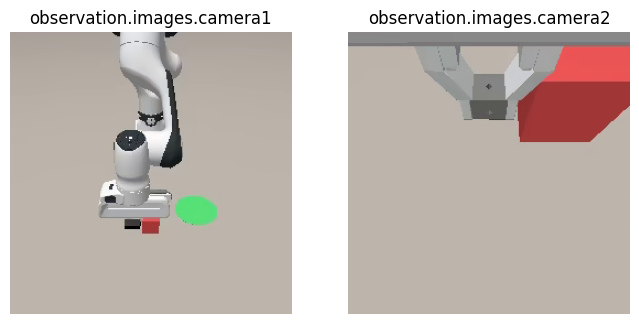

In [5]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset
import matplotlib.pyplot as plt

ds = LeRobotDataset(DATASET_REPO_ID)
print(f"エピソード数: {ds.num_episodes}, フレーム数: {ds.num_frames}, fps: {ds.fps}")
print("特徴量:", list(ds.meta.features))
sample = ds[len(ds) // 2]
print("タスク:", sample["task"])
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, key in zip(axes, ["observation.images.camera1", "observation.images.camera2"]):
    ax.imshow(sample[key].permute(1, 2, 0)); ax.set_title(key); ax.axis("off")
plt.show()

## 5. 学習
`--policy.path=lerobot/smolvla_base` で事前学習済みモデルから始めます．
画像エンコーダと言語モデル部分は固定され，行動を出力する部分（action expert，約1億パラメータ）だけが学習されます．

ログの `loss` が下がっていくことを確認しましょう．`updt_s`（1ステップの時間）から全体の所要時間を見積もれます．

⚠️ このセルをもう一度実行すると「Output directory ... already exists」で止まります．最初からやり直すときは `!rm -rf {OUTPUT_DIR}` を実行してから，続きから学習するときは 7 を使ってください．

In [6]:
!lerobot-train \
  --policy.path=lerobot/smolvla_base \
  --dataset.repo_id={DATASET_REPO_ID} \
  --batch_size={BATCH_SIZE} \
  --steps={STEPS} \
  --save_freq={SAVE_FREQ} \
  --log_freq=50 \
  --num_workers=2 \
  --output_dir={OUTPUT_DIR} \
  --job_name=smolvla_franka_push \
  --policy.device=cuda \
  --policy.repo_id={MODEL_REPO_ID} \
  --policy.push_to_hub=true \
  --save_checkpoint_to_hub=true \
  --wandb.enable=false

config.json: 100% 2.30k/2.30k [00:00<00:00, 6.04MB/s]
INFO 2026-11-01 16:50:38 ot_train.py:272 {'batch_size': 8,
 'checkpoint_path': None,
 'cudnn_deterministic': False,
 'dataloader_multiprocessing_context': 'spawn',
 'dataset': {'depth_output_unit': 'mm',
             'episodes': None,
             'eval_split': 0.0,
             'image_transforms': {'enable': False,
                                  'max_num_transforms': 3,
                                  'random_order': False,
                                  'tfs': {'affine': {'kwargs': {'degrees': [-5.0,
                                                                            5.0],
                                                                'translate': [0.05,
                                                                              0.05]},
                                                     'type': 'RandomAffine',
                                                     'weight': 1.0},
                                

## 6. 学習したモデルの確認（オープンループ）
データセットのある時刻の観測を入力し，予測した行動（50ステップ分）と実際のデモの行動を比べます．
ここで大きくずれている場合，Gazebo で動かしてもうまくいきません．

`torch_dtype` is deprecated! Use `dtype` instead!


Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

Reducing the number of VLM layers to 16 ...
Loading weights from local directory


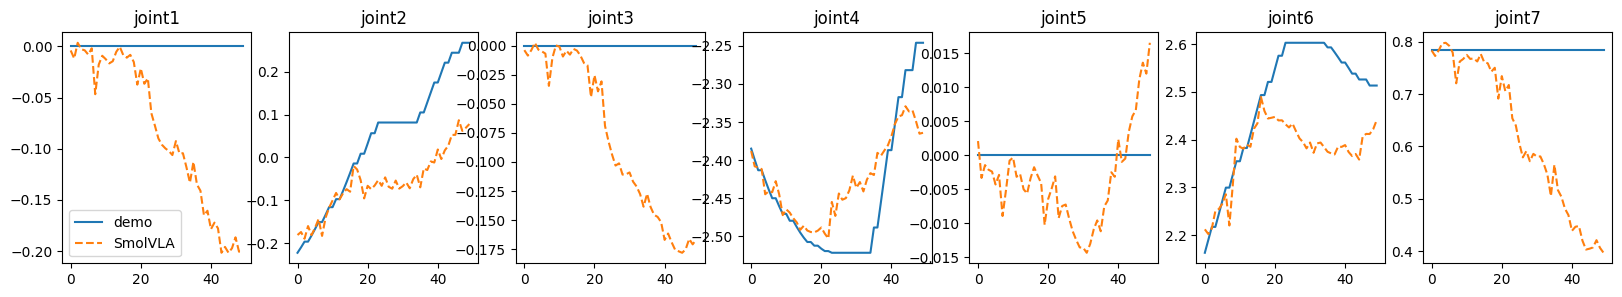

In [7]:
import torch, numpy as np
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
from lerobot.policies.factory import make_pre_post_processors

model_path = f"{OUTPUT_DIR}/checkpoints/last/pretrained_model"
policy = SmolVLAPolicy.from_pretrained(model_path).to("cuda").eval()
pre, post = make_pre_post_processors(policy.config, pretrained_path=model_path,
                                     postprocessor_overrides={"device_processor": {"device": "cpu"}})

ep = 0
start = ds.meta.episodes["dataset_from_index"][ep] + 20
frame = ds[start]
obs = {k: frame[k] for k in ["observation.state", "observation.images.camera1", "observation.images.camera2"]}
obs["task"] = frame["task"]
with torch.inference_mode():
    policy.reset()
    chunk = policy.predict_action_chunk(pre(obs))
    pred = torch.stack([post(chunk[:, i]) for i in range(chunk.shape[1])], dim=1)[0].numpy()
gt = np.stack([ds[start + i]["action"].numpy() for i in range(len(pred))])

fig, axes = plt.subplots(1, 7, figsize=(20, 3))
for j, ax in enumerate(axes):
    ax.plot(gt[:, j], label="demo"); ax.plot(pred[:, j], "--", label="SmolVLA"); ax.set_title(f"joint{j + 1}")
axes[0].legend(); plt.show()

## 7. （切断されたとき）途中から再開する
Colab が切断されたら，1〜3 を実行した後に以下を実行します．
Hub にアップロードされた最新のチェックポイントから学習を再開します．

In [8]:
!lerobot-train \
  --resume=true \
  --config_path={MODEL_REPO_ID} \
  --output_dir={OUTPUT_DIR}

train_config.json: 100% 7.22k/7.22k [00:00<00:00, 13.2MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0% 0/12 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/660 [00:00<?, ?B/s]           

Fetching 12 files:  33% 4/12 [00:00<00:00, 10.25it/s]
Reconstructing (incomplete total...):   8% 660/7.88k [00:00<00:04, 1.71kB/s]
Reconstructing (incomplete total...):  81% 7.88k/9.78k [00:00<00:01, 1.71kB/s]
Reconstructing (incomplete total...):  79% 7.88k/10.0k [00:00<00:01, 1.71kB/s]
Reconstructing (incomplete total...):  53% 10.0k/18.8k [00:00<00:05, 1.71kB/s]
Reconstructing (incomplete total...):  88% 18.8k/21.3k [00:00<00:01, 1.71kB/s]
Reconstructing (incomplete total...): 100% 21.3k/21.4k [00:00<00:00, 1.71kB/s]

Fetching 12 files:  83% 10/12 [00:00<00:00, 14.24it/s]

Fetching 12 files: 100% 12/12 [00:03<00:00,  3.24it/s]
Download complete: 100% 21.4k/21.4k [00:03<00:00, 34.5kB/s]
Reconstruction complete: 100% 21.4k/

学習が終わったら，`smolvla_server.ipynb` の `MODEL_ID` を `MODEL_REPO_ID`（`<ユーザー名>/smolvla_franka_push`）に変えて推論サーバを立て，
Gazebo 上で評価（`ros2 run franka_vla_sim evaluator`）してみましょう．